<a href="https://colab.research.google.com/github/Robin-FIME/InteligenciaArtificial_y_RedesNeuronales_UANL_FIME/blob/main/ACTIVIDADES/AF8_RNC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Actividad 8: Redes Neuronales Convolucionales**
-**Grupo:** 004 -**Horario de clase:** Jueves N1 a N3
* **2066292**	Gabriel Alejandro Almanza Mata	**IMC**

* **2100051**	Alfredo René Robles Guzman	**IMC**

* **2177682**	Luis Mauricio Torres Mayorga **IMC**

* **2111623** Valeria Monserrat Rincón Vásquez **IMC**

* **1930458** Juan Carlos Torres Gonzales **IMC**

In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

print("Versión de TensorFlow:", tf.__version__)

Versión de TensorFlow: 2.21.0


In [2]:
# Cargar el conjunto de datos MNIST
(train_images, train_labels), (test_images, test_labels) = datasets.mnist.load_data()

print(f"Dimensiones de train_images: {train_images.shape}")
print(f"Dimensiones de train_labels: {train_labels.shape}")
print(f"Dimensiones de test_images: {test_images.shape}")
print(f"Dimensiones de test_labels: {test_labels.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dimensiones de train_images: (60000, 28, 28)
Dimensiones de train_labels: (60000,)
Dimensiones de test_images: (10000, 28, 28)
Dimensiones de test_labels: (10000,)


In [3]:
# Normalizar los valores de los píxeles para que estén entre 0 y 1
train_images = train_images / 255.0
test_images = test_images / 255.0

# Redimensionar las imágenes añadiendo el canal (28x28x1) requerido por Conv2D
train_images = train_images.reshape((train_images.shape[0], 28, 28, 1))
test_images = test_images.reshape((test_images.shape[0], 28, 28, 1))

print(f"Nuevas dimensiones de train_images: {train_images.shape}")

Nuevas dimensiones de train_images: (60000, 28, 28, 1)


In [4]:
# Construir la Red Neuronal Convolucional
model = models.Sequential([
    # Primera capa convolucional y de pooling
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),

    # Segunda capa convolucional y de pooling
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Aplanador para pasar de matrices a vector unidimensional
    layers.Flatten(),

    # Capa densa oculta
    layers.Dense(64, activation='relu'),

    # Capa de salida con activación softmax para clasificación multiclase (10 dígitos)
    layers.Dense(10, activation='softmax')
])

# Ver resumen de la arquitectura
model.summary()

# Compilar el modelo
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Entrenar el modelo
EPOCHS = 5
history = model.fit(train_images, train_labels, epochs=EPOCHS, batch_size=64, validation_split=0.1)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 52ms/step - accuracy: 0.9420 - loss: 0.1969 - val_accuracy: 0.9802 - val_loss: 0.0685
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 44s 52ms/step - accuracy: 0.9817 - loss: 0.0595 - val_accuracy: 0.9870 - val_loss: 0.0465
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 51ms/step - accuracy: 0.9869 - loss: 0.0420 - val_accuracy: 0.9868 - val_loss: 0.0420
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 43s 51ms/step - accuracy: 0.9903 - loss: 0.0307 - val_accuracy: 0.9902 - val_loss: 0.0359
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 43s 51ms/step - accuracy: 0.9920 - loss: 0.0246 - val_accuracy: 0.9912 - val_loss: 0.0363


313/313 - 4s - 11ms/step - accuracy: 0.9884 - loss: 0.0316

Exactitud (Accuracy) en el conjunto de prueba: 98.84%
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step

--- Resultados de las 5 predicciones ---
Predicción 1: Modelo predijo -> 7 | Valor real -> 7
Predicción 2: Modelo predijo -> 2 | Valor real -> 2
Predicción 3: Modelo predijo -> 1 | Valor real -> 1
Predicción 4: Modelo predijo -> 0 | Valor real -> 0
Predicción 5: Modelo predijo -> 4 | Valor real -> 4


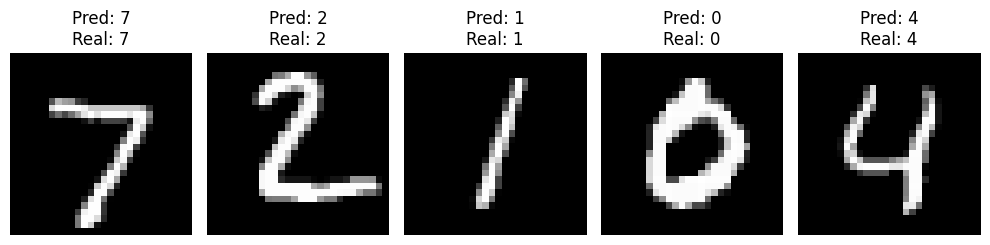

In [5]:
# Evaluar el modelo con el conjunto de prueba
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(f"\nExactitud (Accuracy) en el conjunto de prueba: {test_acc * 100:.2f}%")

# Realizar 5 predicciones diferentes con las primeras imágenes de prueba
num_predictions = 5
predictions = model.predict(test_images[:num_predictions])

print("\n--- Resultados de las 5 predicciones ---")
for i in range(num_predictions):
    pred_label = np.argmax(predictions[i])
    true_label = test_labels[i]
    print(f"Predicción {i+1}: Modelo predijo -> {pred_label} | Valor real -> {true_label}")

# Opcional: Visualizar las imágenes evaluadas
plt.figure(figsize=(10, 3))
for i in range(num_predictions):
    plt.subplot(1, num_predictions, i + 1)
    plt.imshow(test_images[i].reshape(28, 28), cmap='gray')
    pred_label = np.argmax(predictions[i])
    plt.title(o := f"Pred: {pred_label}\nReal: {test_labels[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()